In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [ ]:
df = pd.read_csv("data/drug_release_data.csv")
df

In [ ]:
df.info()

In [ ]:
df.describe()

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [4]:
df = pd.read_csv("drug_release_data.csv")

df

,time_hours,drug_released_percent
0,0,0.0
1,1,8.4
2,2,15.7
3,4,27.9
4,6,38.1
5,8,46.5
6,12,59.8
7,16,69.2
8,20,76.4
9,24,82.1


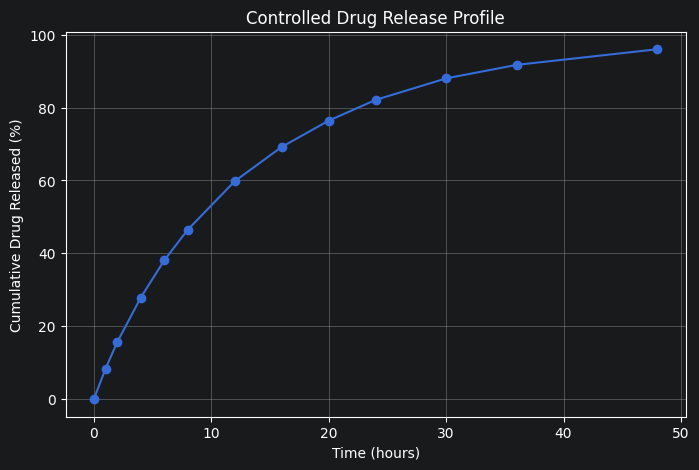

In [5]:
plt.figure(figsize=(8, 5))

plt.plot(
    df["time_hours"],
    df["drug_released_percent"],
    marker="o"
)

plt.xlabel("Time (hours)")
plt.ylabel("Cumulative Drug Released (%)")
plt.title("Controlled Drug Release Profile")
plt.grid(True)

plt.show()

## Kinetic Model Fitting

To characterize the simulated drug-release profile, three common release models were evaluated: zero-order, first-order, and Higuchi kinetics.

In [6]:
def zero_order(t, k0):
    return k0 * t


def first_order(t, q_inf, k):
    return q_inf * (1 - np.exp(-k * t))


def higuchi(t, k_h):
    return k_h * np.sqrt(t)

In [7]:
time = df["time_hours"].values
release = df["drug_released_percent"].values

In [8]:
# Fit zero-order model
zero_params, _ = curve_fit(zero_order, time, release)
k0 = zero_params[0]

# Fit first-order model
first_params, _ = curve_fit(
    first_order,
    time,
    release,
    p0=[100, 0.1],
    bounds=(0, np.inf)
)
q_inf, k1 = first_params

# Fit Higuchi model
higuchi_params, _ = curve_fit(higuchi, time, release)
k_h = higuchi_params[0]

print(f"Zero-order k0: {k0:.3f}")
print(f"First-order Q∞: {q_inf:.3f}")
print(f"First-order k: {k1:.3f}")
print(f"Higuchi kH: {k_h:.3f}")

Zero-order k0: 2.772
First-order Q∞: 96.719
First-order k: 0.081
Higuchi kH: 15.635


In [9]:
zero_pred = zero_order(time, k0)
first_pred = first_order(time, q_inf, k1)
higuchi_pred = higuchi(time, k_h)

In [10]:
def calculate_metrics(actual, predicted):
    residuals = actual - predicted

    ss_res = np.sum(residuals ** 2)
    ss_tot = np.sum((actual - np.mean(actual)) ** 2)

    r_squared = 1 - (ss_res / ss_tot)
    rmse = np.sqrt(np.mean(residuals ** 2))

    return r_squared, rmse


zero_r2, zero_rmse = calculate_metrics(release, zero_pred)
first_r2, first_rmse = calculate_metrics(release, first_pred)
higuchi_r2, higuchi_rmse = calculate_metrics(release, higuchi_pred)

print(f"Zero-order:  R² = {zero_r2:.4f}, RMSE = {zero_rmse:.2f}")
print(f"First-order: R² = {first_r2:.4f}, RMSE = {first_rmse:.2f}")
print(f"Higuchi:     R² = {higuchi_r2:.4f}, RMSE = {higuchi_rmse:.2f}")

Zero-order:  R² = 0.6303, RMSE = 19.48
First-order: R² = 0.9993, RMSE = 0.85
Higuchi:     R² = 0.9685, RMSE = 5.69


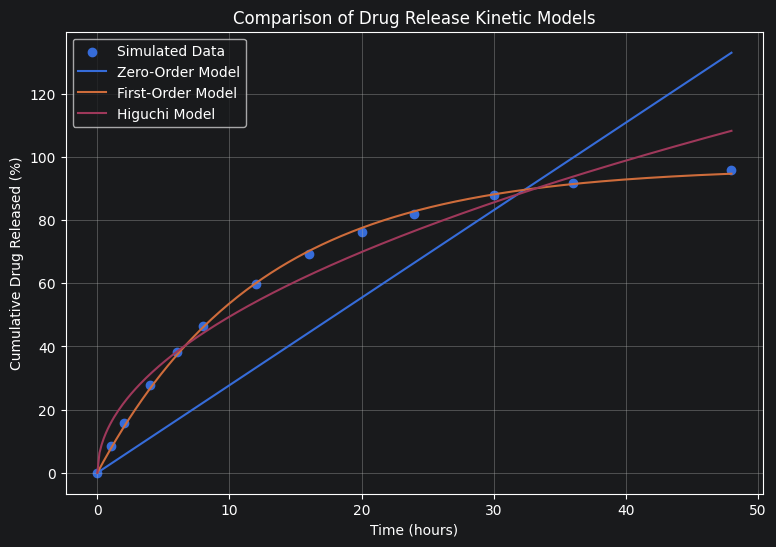

In [15]:
time_smooth = np.linspace(0, time.max(), 300)

plt.figure(figsize=(9, 6))

plt.scatter(
    time,
    release,
    label="Simulated Data"
)

plt.plot(
    time_smooth,
    zero_order(time_smooth, k0),
    label="Zero-Order Model"
)

plt.plot(
    time_smooth,
    first_order(time_smooth, q_inf, k1),
    label="First-Order Model"
)

plt.plot(
    time_smooth,
    higuchi(time_smooth, k_h),
    label="Higuchi Model"
)

plt.xlabel("Time (hours)")
plt.ylabel("Cumulative Drug Released (%)")
plt.title("Comparison of Drug Release Kinetic Models")

plt.legend()
plt.grid(True)

plt.savefig(
    "model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Model Performance

Model fit was evaluated using the coefficient of determination (R²) and root mean squared error (RMSE). A higher R² and lower RMSE indicate better agreement between the model and the simulated release data.

In [12]:
def calculate_metrics(actual, predicted):
    residuals = actual - predicted

    ss_res = np.sum(residuals ** 2)
    ss_tot = np.sum((actual - np.mean(actual)) ** 2)

    r_squared = 1 - (ss_res / ss_tot)
    rmse = np.sqrt(np.mean(residuals ** 2))

    return r_squared, rmse


zero_r2, zero_rmse = calculate_metrics(release, zero_pred)
first_r2, first_rmse = calculate_metrics(release, first_pred)
higuchi_r2, higuchi_rmse = calculate_metrics(release, higuchi_pred)

results = pd.DataFrame({
    "Model": ["Zero-order", "First-order", "Higuchi"],
    "R²": [zero_r2, first_r2, higuchi_r2],
    "RMSE": [zero_rmse, first_rmse, higuchi_rmse]
})

results

,Model,R²,RMSE
0,Zero-order,0.630290,19.484586
1,First-order,0.999300,0.848057
2,Higuchi,0.968513,5.686223


In [13]:
t50 = np.log(2) / k1

print(f"Estimated t50: {t50:.2f} hours")

Estimated t50: 8.57 hours


## Interpretation

The first-order model provided the best fit to the simulated drug-release data, with an R² of 0.9993 and an RMSE of 0.85 percentage points. This indicates that the first-order model closely reproduced the observed release profile.

The fitted first-order model predicted a maximum cumulative release of approximately 96.7% and a release-rate constant of approximately 0.081 h⁻¹.

The estimated t50 was 8.57 hours, meaning that approximately half of the model's eventual drug release occurred within the first 8.6 hours.

The Higuchi model also captured the general release behavior, achieving an R² of 0.9685 and an RMSE of 5.69, but showed greater deviation at later time points.

The zero-order model performed substantially worse, with an R² of 0.6303 and an RMSE of 19.48. Its assumption of a constant release rate does not capture the plateauing behavior of this simulated dataset.

Because the dataset is simulated, these results demonstrate the model-fitting and analysis workflow rather than conclusions about a real drug-delivery formulation.